# Step 6 — Evaluasi Sistem Temu Kembali Informasi

**Tujuan praktikum**
1. Mahasiswa memahami koleksi uji: dokumen, query, dan *relevance judgment* (qrels).
2. Mahasiswa mampu menghitung precision, recall, F1, P@k, *Average Precision* (AP), MAP, dan nDCG.
3. Mahasiswa mampu membandingkan kinerja model Boolean, TF-IDF, dan BM25 secara kuantitatif.

**Koleksi uji**: 8 query di `../data/queries.csv` dan penilaian relevansi di `../data/qrels.csv` dengan skala 2 = sangat relevan, 1 = relevan sebagian, dokumen yang tidak tercantum = tidak relevan (0).

In [1]:
# Jalankan sekali jika pustaka belum terpasang:
# !pip install pandas numpy matplotlib Sastrawi
import pandas as pd
pd.set_option("display.max_colwidth", 120)

In [2]:
import math
import matplotlib.pyplot as plt
from stki_utils import (corpus_texts, preprocess, build_inverted_index, boolean_search,
                        TfidfModel, BM25Model, load_queries, load_qrels)

docs = {d: preprocess(t) for d, t in corpus_texts().items()}
queries = load_queries()
qrels = load_qrels()
pd.DataFrame([(q, t, qrels[q]) for q, t in queries.items()], columns=["query_id", "query", "relevansi"])

,query_id,query,relevansi
0,Q1,pencegahan penyakit demam berdarah,"{'D01': 2, 'D05': 1}"
1,Q2,teknologi pertanian modern,"{'D10': 2, 'D09': 2, 'D07': 1, 'D08': 1}"
2,Q3,gizi anak balita,"{'D02': 2, 'D30': 2, 'D05': 1}"
3,Q4,mesin pencari dan indeks dokumen,"{'D13': 2, 'D29': 2, 'D17': 1}"
4,Q5,pemasaran digital UMKM,"{'D19': 2, 'D21': 1, 'D22': 1}"
5,Q6,keamanan data pribadi di internet,"{'D15': 2, 'D27': 1, 'D06': 1}"
6,Q7,harga hasil panen petani,"{'D12': 2, 'D07': 1, 'D23': 1, 'D20': 1}"
7,Q8,pembelajaran daring mahasiswa,"{'D25': 2, 'D28': 1, 'D26': 1}"


## Langkah 1 — Precision, recall, dan F1 untuk hasil tak berperingkat
$$P = \frac{|\text{relevan} \cap \text{ditemukan}|}{|\text{ditemukan}|} \qquad R = \frac{|\text{relevan} \cap \text{ditemukan}|}{|\text{relevan}|} \qquad F_1 = \frac{2PR}{P+R}$$

In [3]:
def prf(ditemukan, relevan):
    tp = len(set(ditemukan) & set(relevan))
    p = tp / len(ditemukan) if ditemukan else 0.0
    r = tp / len(relevan) if relevan else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f1

index = build_inverted_index(docs)
baris = []
for q, teks in queries.items():
    terms = preprocess(teks)
    for op in ["AND", "OR"]:
        hasil = boolean_search(f" {op} ".join(terms), index, list(docs))
        p, r, f1 = prf(hasil, qrels[q])
        baris.append({"query_id": q, "operator": op, "ditemukan": len(hasil), "P": p, "R": r, "F1": f1})
bool_df = pd.DataFrame(baris)
bool_df.groupby("operator")[["ditemukan", "P", "R", "F1"]].mean().round(4)

,ditemukan,P,R,F1
operator,,,,
AND,0.5,0.5000,0.1667,0.2500
OR,6.5,0.5112,0.9167,0.6145


Boolean AND cenderung *precision* tinggi tetapi *recall* rendah (banyak query kosong), sedangkan OR sebaliknya. Inilah *trade-off* precision–recall.

## Langkah 2 — Metrik untuk hasil berperingkat
Kita ambil satu query sebagai contoh perhitungan langkah demi langkah.

In [4]:
bm25 = BM25Model(docs)
q = "Q2"
ranking = [d for d, _ in bm25.search(preprocess(queries[q]), k=10)]
relevan = qrels[q]

langkah, hits = [], 0
for i, d in enumerate(ranking, start=1):
    rel = d in relevan
    hits += rel
    langkah.append({"rank": i, "doc_id": d, "relevan": relevan.get(d, 0),
                    "P@i": hits / i, "R@i": hits / len(relevan), "P@i (jika relevan)": hits / i if rel else None})
tabel = pd.DataFrame(langkah).set_index("rank")
print("Query:", queries[q], "| dokumen relevan:", relevan)
tabel.round(4)

Query: teknologi pertanian modern | dokumen relevan: {'D10': 2, 'D09': 2, 'D07': 1, 'D08': 1}


,doc_id,relevan,P@i,R@i,P@i (jika relevan)
rank,,,,,
1,D10,2,1.0000,0.25,1.0000
2,D12,0,0.5000,0.25,NaN
3,D06,0,0.3333,0.25,NaN
4,D27,0,0.2500,0.25,NaN
5,D08,1,0.4000,0.50,0.4000
6,D09,2,0.5000,0.75,0.5000
7,D07,1,0.5714,1.00,0.5714
8,D23,0,0.5000,1.00,NaN
9,D11,0,0.4444,1.00,NaN


**Average Precision (AP)** adalah rata-rata nilai P@i pada posisi dokumen relevan, dibagi jumlah seluruh dokumen relevan (dokumen relevan yang tidak ditemukan menyumbang 0). **MAP** adalah rata-rata AP seluruh query.

In [5]:
ap = tabel["P@i (jika relevan)"].sum() / len(relevan)
nilai = [round(x, 4) for x in tabel["P@i (jika relevan)"].dropna()]
print(f"AP({q}) = sum({nilai}) / {len(relevan)} = {ap:.4f}")

AP(Q2) = sum([1.0, 0.4, 0.5, 0.5714]) / 4 = 0.6179


**nDCG@k** memperhitungkan relevansi bertingkat dan posisi:
$$DCG@k = \sum_{i=1}^{k} \frac{rel_i}{\log_2(i+1)} \qquad nDCG@k = \frac{DCG@k}{IDCG@k}$$
IDCG adalah DCG dari urutan ideal (semua dokumen paling relevan di atas).

In [6]:
k = 5
gains = [relevan.get(d, 0) for d in ranking[:k]]
ideal = sorted(relevan.values(), reverse=True)[:k]
dcg = sum(g / math.log2(i + 1) for i, g in enumerate(gains, start=1))
idcg = sum(g / math.log2(i + 1) for i, g in enumerate(ideal, start=1))
print("gain hasil :", gains, f"-> DCG@{k}  = {dcg:.4f}")
print("gain ideal :", ideal, f"-> IDCG@{k} = {idcg:.4f}")
print(f"nDCG@{k} = {dcg / idcg:.4f}")

gain hasil : [2, 0, 0, 0, 1] -> DCG@5  = 2.3869
gain ideal : [2, 2, 1, 1] -> IDCG@5 = 4.1925
nDCG@5 = 0.5693


## Langkah 3 — Evaluasi seluruh query
Fungsi `stki_utils.evaluate` menghitung P@k, R@k, F1@k, AP, dan nDCG@k untuk setiap query, ditambah baris rata-rata (rata-rata kolom AP = **MAP**).

In [7]:
from stki_utils import evaluate, average_precision, ndcg_at_k

tfidf = TfidfModel(docs)
run_tfidf = {q: [d for d, _ in tfidf.search(preprocess(t), k=10)] for q, t in queries.items()}
run_bm25 = {q: [d for d, _ in bm25.search(preprocess(t), k=10)] for q, t in queries.items()}

# cek konsistensi dengan perhitungan manual di atas
assert abs(average_precision(run_bm25["Q2"], set(qrels["Q2"])) - ap) < 1e-9
assert abs(ndcg_at_k(run_bm25["Q2"], qrels["Q2"], 5) - dcg / idcg) < 1e-9

evaluate(run_bm25, qrels, k=5)

,P@5,R@5,F1@5,AP,nDCG@5
query_id,,,,,
Q1,0.4,1.0000,0.5714,0.7500,0.9239
Q2,0.4,0.5000,0.4444,0.6179,0.5693
Q3,0.4,0.6667,0.5000,0.6667,0.8671
Q4,0.4,0.6667,0.5000,0.5556,0.7975
Q5,0.6,1.0000,0.7500,1.0000,1.0000
Q6,0.4,0.6667,0.5000,0.8095,0.8403
Q7,0.8,1.0000,0.8889,1.0000,1.0000
Q8,0.6,1.0000,0.7500,0.8056,0.9360
Rata-rata,0.5,0.8125,0.6131,0.7756,0.8668


## Langkah 4 — Membandingkan model

In [8]:
# Boolean OR diurutkan berdasarkan doc_id (tidak ada skor) sebagai baseline tanpa peringkat
run_bool = {q: boolean_search(" OR ".join(preprocess(t)), index, list(docs))[:10] for q, t in queries.items()}

ringkasan = pd.DataFrame({
    "Boolean OR": evaluate(run_bool, qrels, k=5).loc["Rata-rata"],
    "TF-IDF (VSM)": evaluate(run_tfidf, qrels, k=5).loc["Rata-rata"],
    "BM25": evaluate(run_bm25, qrels, k=5).loc["Rata-rata"],
}).T.rename(columns={"AP": "MAP"})
ringkasan

,P@5,R@5,F1@5,MAP,nDCG@5
Boolean OR,0.45,0.7396,0.5541,0.6511,0.6955
TF-IDF (VSM),0.50,0.8125,0.6131,0.7620,0.8622
BM25,0.50,0.8125,0.6131,0.7756,0.8668


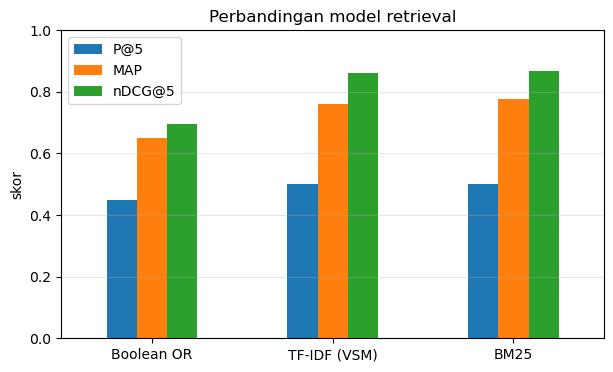

In [9]:
ax = ringkasan[["P@5", "MAP", "nDCG@5"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("skor"); ax.set_title("Perbandingan model retrieval")
ax.grid(axis="y", alpha=.3); plt.show()

## Langkah 5 — Kurva precision–recall terinterpolasi 11 titik

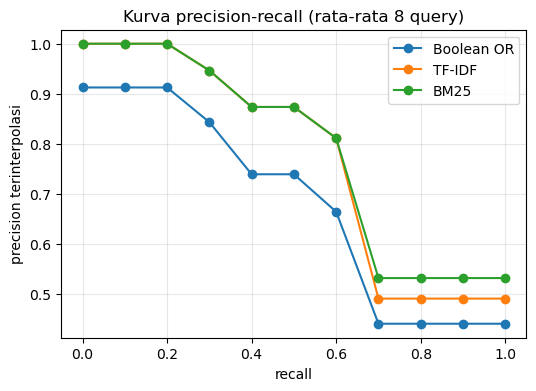

In [10]:
def interpolated_pr(ranking, relevan):
    titik, hits = [], 0
    for i, d in enumerate(ranking, start=1):
        if d in relevan:
            hits += 1
        titik.append((hits / len(relevan), hits / i))
    return [max([p for r, p in titik if r >= level], default=0.0) for level in [i / 10 for i in range(11)]]

level = [i / 10 for i in range(11)]
plt.figure(figsize=(6, 4))
for nama, run in [("Boolean OR", run_bool), ("TF-IDF", run_tfidf), ("BM25", run_bm25)]:
    kurva = [sum(v) / len(v) for v in zip(*(interpolated_pr(run[q], set(qrels[q])) for q in queries))]
    plt.plot(level, kurva, marker="o", label=nama)
plt.xlabel("recall"); plt.ylabel("precision terinterpolasi")
plt.title("Kurva precision-recall (rata-rata 8 query)")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Tugas Step 6
1. Tambahkan 4 query baru beserta relevance judgment-nya ke `qrels.csv` (diskusikan penilaian dengan rekan satu kelompok). Laporkan tingkat kesepakatan penilai.
2. Hitung **R-Precision** dan **Mean Reciprocal Rank (MRR)** untuk ketiga model.
3. Query mana yang kinerjanya paling buruk pada BM25? Lakukan analisis kegagalan (*failure analysis*): apakah penyebabnya preprocessing, ketidakcocokan kosakata (*vocabulary mismatch*), atau penilaian relevansi?
4. Gunakan fungsi evaluasi untuk menyelesaikan grid search $k_1$ dan $b$ pada Tugas Step 5.

In [11]:
# Tulis jawaban Anda di sini